# Analysis of the alignment results

After running the Monte Carlo, we have obtained our results, stored in `.pkl` files with the following information:
* E: with all energies per MC step for each replica (different temperatures)
* E_GT: energy of the ground truth alignment
* GS: ground state permutation (replica with lowest energy)
* Samples: ensemble of permutations (from replica at temperature 1)

We will analyze the alignment of **C. elegans** with groups — this corresponds to a *group-guided alignment*,  
where groups are defined based on the **location of each neuron**.

However, if one wishes to analyze the alignment **without groups**,  
it is as simple as calling the same function **without passing the `groups` argument**  
(since `groups` is set to `None` by default).

In [1]:
from aligner.networksHandling import helper as helper_networks
from aligner.poissonAlignment import helper as helper_poisson
from aligner.analysis import helper as helper_analysis
from aligner.montecarlo import helper as helper_montecarlo

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle

## 1. C. elegans (with groups)

In [3]:
labels = ["L2", "L3", "A.1", "A.2"]

In [4]:
file_results = "results/celegans/groups_"
R = 5 #number of runs

beta_spacing = 1.005
betas = np.array([beta_spacing**n for n in range(-12,1)])

all_results = []
for run in range(R):
    #append results:
    with open(f"{file_results}run{run}.pkl", "rb") as file:
        results = pickle.load(file)
    all_results.append(results)

### 1.1. Energy assessment:

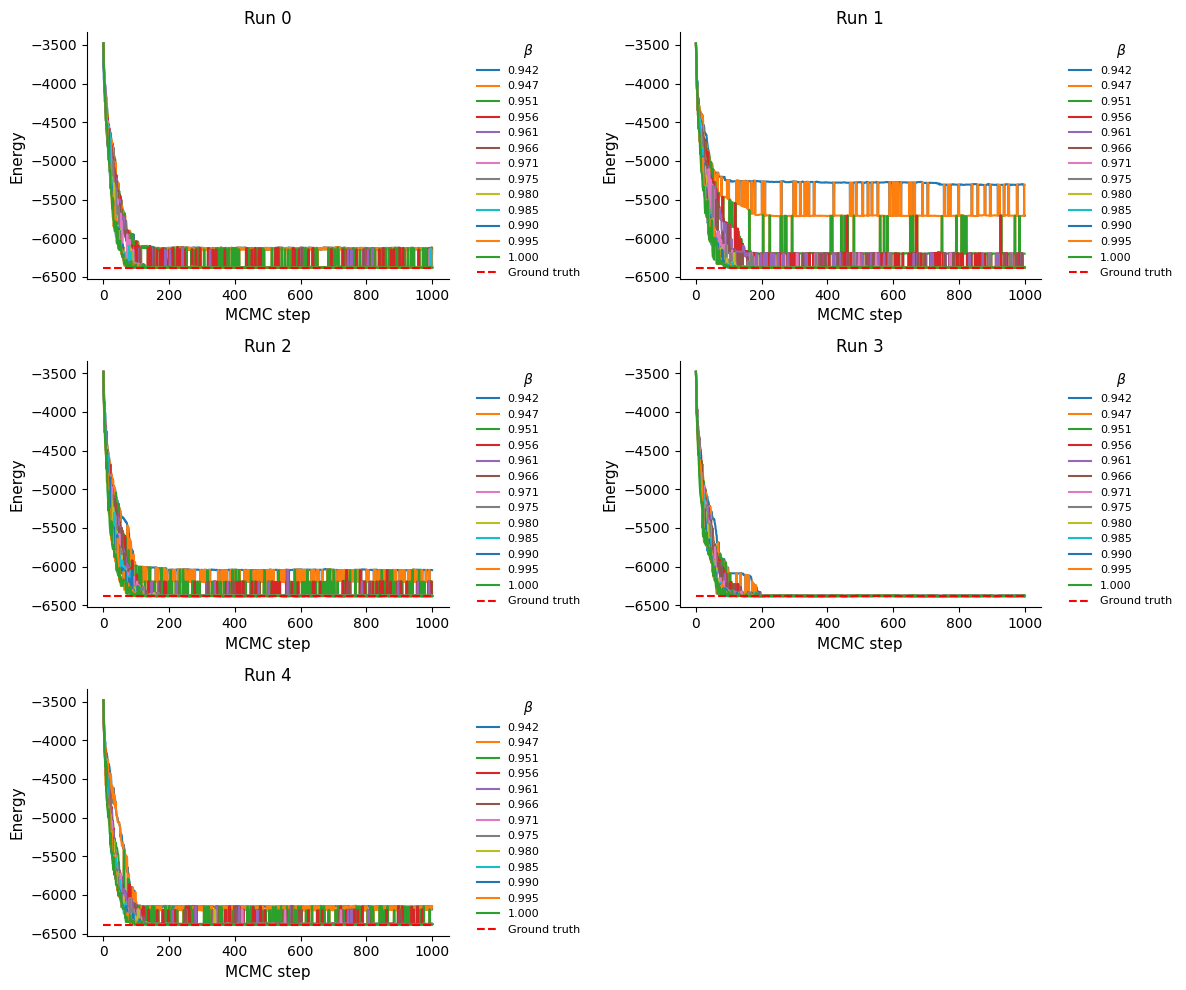

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
axes = axes.flatten()

for run in range(R):
    ax = axes[run]
    for b, beta in enumerate(betas):
        ax.plot(all_results[run]["E"][b], label=f"{beta:.3f}")
    
    ax.plot([results["E_GT"]] * len(all_results[run]["E"][0]), 'r--', label="Ground truth")
    ax.set_title(f"Run {run}", fontsize=12)
    ax.set_xlabel("MCMC step", fontsize=11); ax.set_ylabel("Energy", fontsize=11)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.legend(title=r"$\beta$", fontsize=8, frameon=False, bbox_to_anchor=(1.05, 1), loc='upper left')

axes[5].axis('off')
plt.tight_layout()
plt.show()

## 1.2. Inferred node mapping (comparison with ground truth)

We know that the ground truth in this case corresponds to the permutation with the same order of nodes in each snapshot/layer. 

We consider the inferred node mapping from the ensemble of permutations sampled at $\beta=1$.

In [6]:
print(f"One of the sampled permutations at equilibrium: \n{all_results[0]['Samples'][-1]}")

One of the sampled permutations at equilibrium: 
[[12 10 20 32 44  4  6 38 18  0 28 14 30 48 42 52  8 56 36 34 16 25 58 40
  50 23 46 54  2 59 22 13 11 21 29  7 19 53 31 15 45 24 57 33  1 26 47 39
  55 51 43 17 35  5 41 27 49  9 37  3]
 [12 10 20 32 44  4  6 38 18  0 28 14 30 48 42 52  8 56 36 34 16 25 58 40
  50 23 46 54  2 59 22 13 11 21 29  7 19 53 31 15 45 24 57 33  1 26 47 39
  55 51 43 17 35  5 41 27 49  9 37  3]
 [12 10 20 32 44  4  6 38 18  0 28 14 30 48 42 52  8 56 36 34 16 25 58 40
  50 23 46 54  2 59 22 13 11 21 29  7 19 53 31 15 45 24 57 33  1 26 47 39
  55 51 43 17 35  5 41 27 49  9 37  3]
 [12 10 20 32 44  4  6 38 18  0 28 14 30 48 42 52  8 56 36 34 16 23 58 40
  50 25 46 54  2 59 22 13 11 21 29  7 19 53 31 15 45 24 57 33  1 26 47 39
  55 51 43 17 35  5 41 27 49  9 37  3]]


In [7]:
S, T, N = all_results[0]["Samples"].shape #number of samples in one run (S), snapshots (T), and nodes (N)

In [8]:
ensemble = np.zeros((S*R, T, N)) 
for run in range(R):
    run_samples = all_results[run]["Samples"]
    ensemble[run*S:(run+1)*S, :, :] = run_samples

In [9]:
ensemble.shape

(1250, 4, 60)

In [10]:
ensemble_node_mapping = helper_analysis.infer_node_mapping(ensemble)

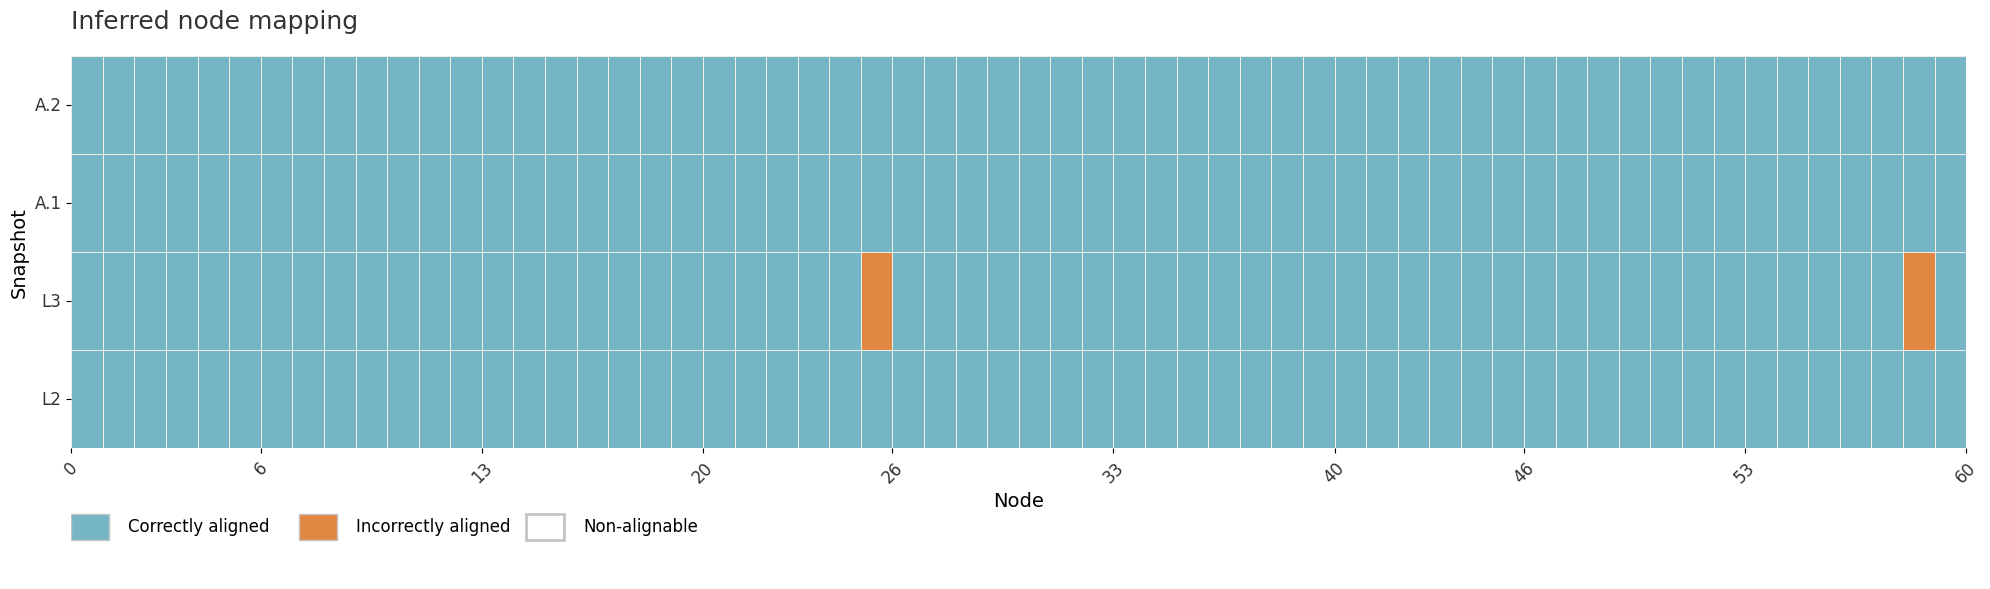

In [11]:
helper_analysis.show_alignment(ensemble_node_mapping, N, T, True, True, labels, "Inferred node mapping");

Once we have the comparison between the inferred alignment and the ground truth, we want to get rid of the **non-alignable nodes** (those that are disconnected, and therefore can not be aligned) and we want to **order the nodes by strength** in the densest snapshot (to ease visualization).

For that, we must load the network we have aligned.

In this way, we will also have the nodes grouped in the same groups we used for the group-guided alginment, if applicable.

In [12]:
net_ids = [5,6,7,8] #snapshots we want to align
T = len(net_ids)
A = helper_networks.load_networks(data_folder="data/celegans/", 
                                  net_ids=net_ids,
                                  file_prefix="reduced_")


#groups info:
neuron_metadata = pd.read_csv("data/celegans/reduced_neuron_metadata.csv", index_col=0) #neuron order in adj mats
groups = np.array(neuron_metadata["location"])

In [13]:
ensemble_node_mapping = helper_analysis.mark_empty_nodes(ensemble_node_mapping, A)
ensemble_node_mapping = helper_analysis.order_node_mapping(ensemble_node_mapping, A, groups)

Groups: ['Left' 'Other' 'Right']
Group boundary array: [ 0 29 31 60]


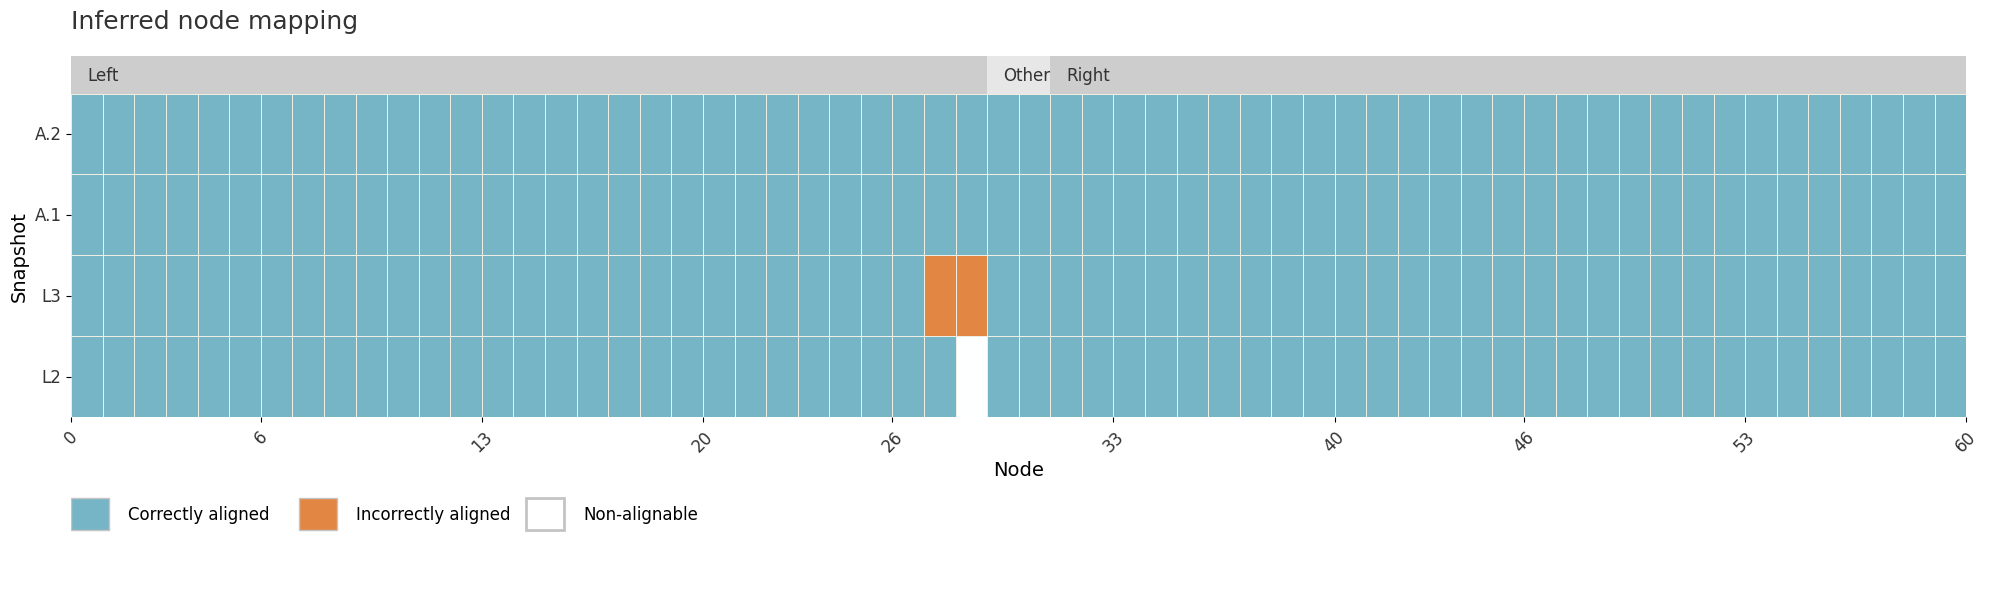

In [14]:
helper_analysis.show_alignment(ensemble_node_mapping, N, T, True, True, labels, "Inferred node mapping", groups);
#non-alignable: white

In [15]:
accuracy = helper_analysis.compute_accuracy(ensemble_node_mapping) #disregarding non-alignable nodes
print(f"Accuracy of the ensemble alignment = {accuracy}")

Accuracy of the ensemble alignment = 0.9916317991631799


### 1.3. Inferred blueprint

We consider the inferred  blueprint as the average over the ensemble of permutations. We compute the blueprint of each permutation and then compute the mean of each $L_{ij}$ following the latent assignment vector of each alignment.

In [16]:
inferred_blueprint = helper_analysis.infer_blueprint(A, ensemble)

In [17]:
#compare to ground truth-blueprint:
gt_P = np.array([[n for n in range (N)] for t in range(T)]) #GT permutation is the same permutation for each snapshot
gt_blueprint = helper_poisson.get_L(A, gt_P, helper_poisson.get_Salpha(A), N, T)

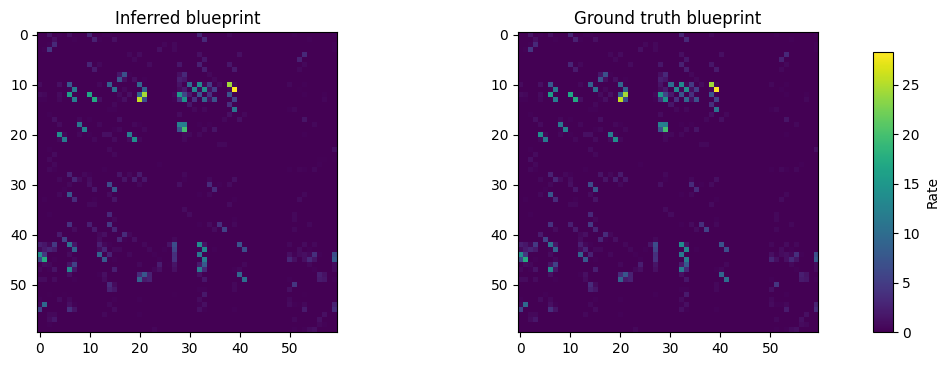

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
vmin, vmax = np.min([inferred_blueprint, gt_blueprint]), np.max([inferred_blueprint, gt_blueprint])
titles = ["Inferred blueprint", "Ground truth blueprint"]
for ax, L, t in zip(axes, [inferred_blueprint, gt_blueprint], titles):
    im = ax.imshow(L, cmap="viridis", vmin=vmin, vmax=vmax)
    ax.set_title(t)
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7]) 
fig.colorbar(im, cax=cbar_ax, label="Rate")
fig.subplots_adjust(left=0.05, right=0.9, wspace=0.3, top=0.9, bottom=0.15)
plt.show()

### 1.4. Comparing inferred model rates with the original counts

We compare the resulting model rates (from the inferred blueprint and inferred developmental parameters of each connectome) with the real counts.

In [19]:
df_comparison = helper_analysis.compute_counts_vs_model_df(A, inferred_blueprint, labels, bins=10) #binned df
df_comparison.head()

,Network,mean_RealCounts,std_RealCounts,mean_ModelRates,std_ModelRates,err_ModelRates
0,L2,0.333333,0.690929,0.342393,0.344996,0.015747
1,L2,2.068182,1.020664,2.076086,0.445980,0.067234
2,L2,4.260870,1.543826,3.848808,0.364494,0.076002
3,L2,4.937500,2.235136,5.263990,0.408897,0.102224
4,L2,7.105263,2.354540,6.938348,0.526223,0.120724


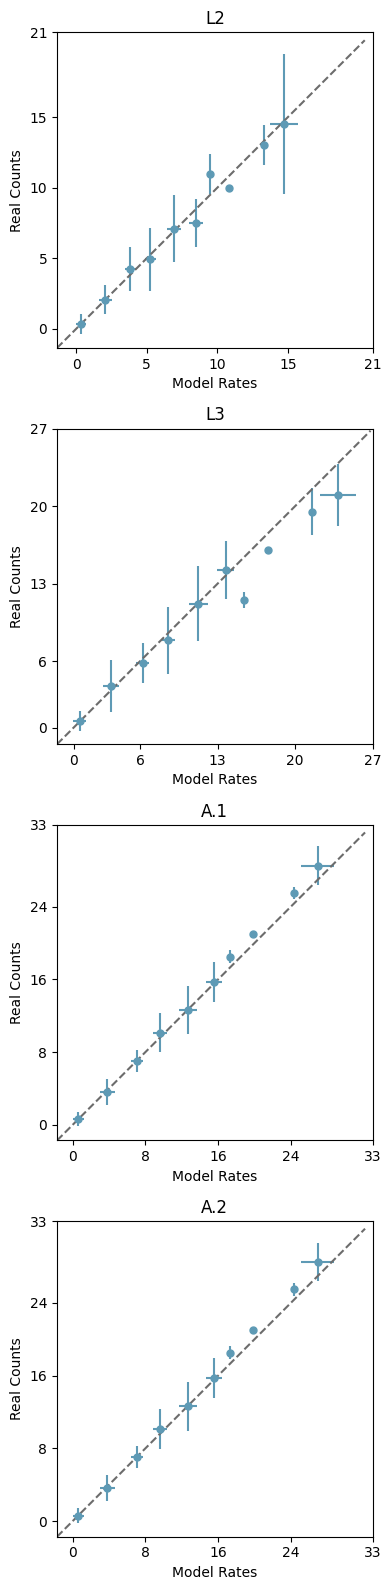

In [20]:
helper_analysis.plot_counts_vs_model(df_comparison)